# TP Vision Artificielle – Noyaux et filtres
Mehdi Moussaid


In [5]:
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1. Noyaux / matrices de convolution
### Question 1 – Fonction `convolution` (avec padding pour conserver la taille)

In [6]:
def convolution(m, c):
    """Retourne M (x) C avec padding (taille conservée).
    m : image (n,p) gris ou (n,p,3) couleur, uint8
    c : noyau kxk (k impair), float
    """
    c = np.asarray(c, dtype=float)
    gris = (m.ndim == 2)
    if gris:
        m = m[:, :, None]
    n, p, q = m.shape
    k = c.shape[0]
    r = k // 2

    # padding : on recopie les bords pour garder la taille
    mp = np.pad(m.astype(float), ((r, r), (r, r), (0, 0)), mode='edge')

    s = np.zeros((n, p, q))
    for u in range(k):
        for v in range(k):
            s += c[u, v] * mp[u:u + n, v:v + p, :]

    # saturation : <0 -> 0 ; >255 -> 255
    mm = np.clip(s, 0, 255).astype(np.uint8)
    return mm[:, :, 0] if gris else mm

### Question 2 – `lissage`, `contraste`, `repoussage`

In [7]:
C1 = np.ones((3, 3)) / 9                                      # lissage
C2 = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float)   # contraste
C3 = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], float)    # repoussage

def lissage(im):
    return convolution(im, C1)

def contraste(im):
    return convolution(im, C2)

def repoussage(im):
    return convolution(im, C3)

In [8]:
img_color = cv2.imread('aero1.jpg')
if img_color is None:
    from skimage import data
    img_color = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)

image = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)   # pour matplotlib

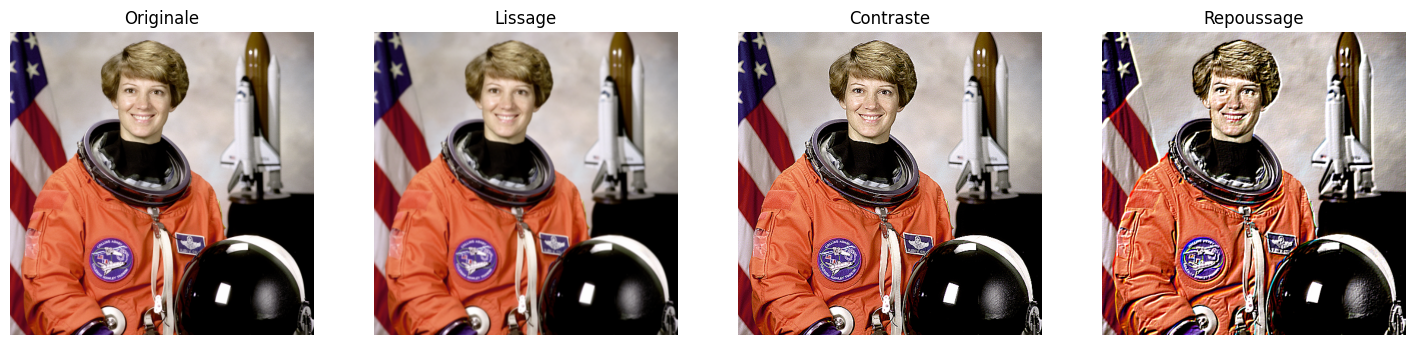

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for a, (t, im) in zip(ax, [("Originale", image), ("Lissage", lissage(image)),
                           ("Contraste", contraste(image)),
                           ("Repoussage", repoussage(image))]):
    a.imshow(im); a.set_title(t); a.axis('off')
plt.show()

## 2. Ajout de bruit poivre et sel

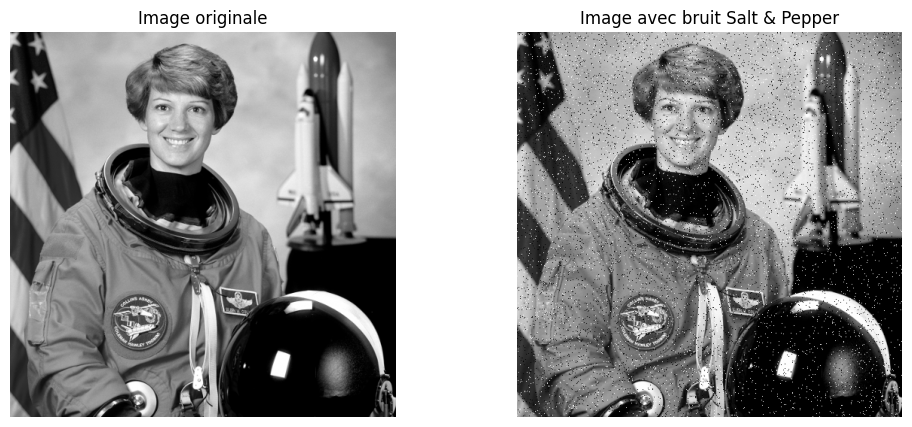

True

In [10]:
img = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
noisy_img = img.copy()
row, col = noisy_img.shape

# Sel (blanc)
number_of_white_pixels = random.randint(300, 10000)
for i in range(number_of_white_pixels):
    y_coord = random.randint(0, row - 1)
    x_coord = random.randint(0, col - 1)
    noisy_img[y_coord][x_coord] = 255

# Poivre (noir)
number_of_black_pixels = random.randint(300, 10000)
for i in range(number_of_black_pixels):
    y_coord = random.randint(0, row - 1)
    x_coord = random.randint(0, col - 1)
    noisy_img[y_coord][x_coord] = 0

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img, cmap='gray');       ax[0].set_title('Image originale'); ax[0].axis('off')
ax[1].imshow(noisy_img, cmap='gray'); ax[1].set_title('Image avec bruit Salt & Pepper'); ax[1].axis('off')
plt.show()

cv2.imwrite('noisy_image.png', noisy_img)

**Question 1 :** oui, le bruit change à chaque exécution (positions et nombres aléatoires). Pour le fixer : `random.seed(0)`.

**Question 2 :** histogramme de l'image bruitée.

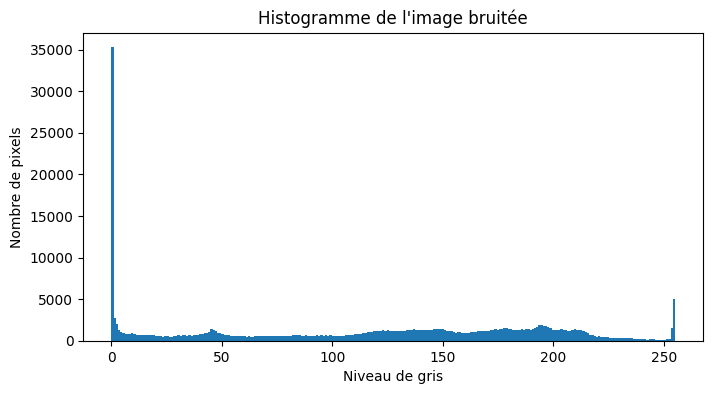

In [11]:
plt.figure(figsize=(8, 4))
plt.hist(noisy_img.ravel(), bins=256, range=(0, 255))
plt.title("Histogramme de l'image bruitée")
plt.xlabel("Niveau de gris"); plt.ylabel("Nombre de pixels")
plt.show()
# Deux pics à 0 et 255 = poivre et sel

## 3. Filtre moyenneur
### Méthode 1 : `cv2.filter2D()`

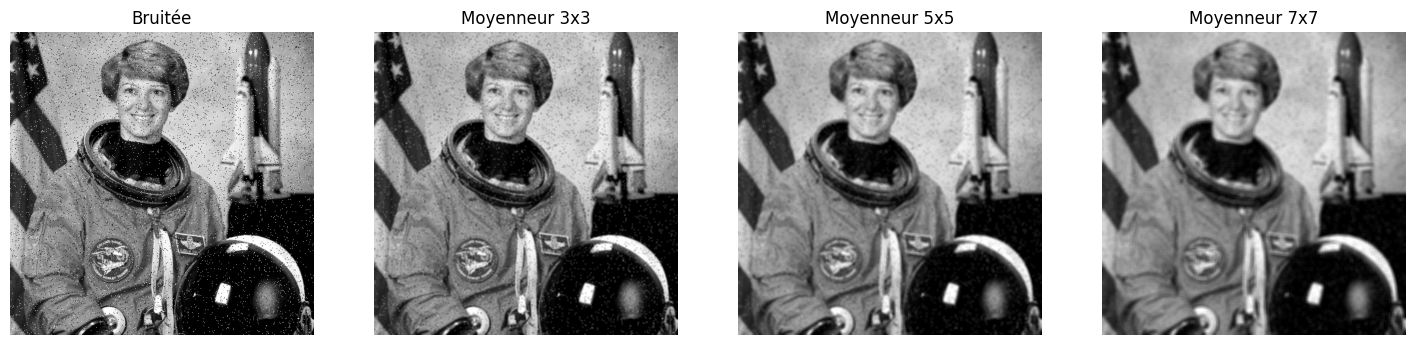

In [12]:
img = cv2.imread('noisy_image.png', 0)
ref = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)   # image propre (pour le PSNR)

kernel_3x3 = np.ones((3, 3), np.float32) / 9
kernel_5x5 = np.ones((5, 5), np.float32) / 25
kernel_7x7 = np.ones((7, 7), np.float32) / 49

filtered_3x3 = cv2.filter2D(img, -1, kernel_3x3)
filtered_5x5 = cv2.filter2D(img, -1, kernel_5x5)
filtered_7x7 = cv2.filter2D(img, -1, kernel_7x7)

fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for a, (t, im) in zip(ax, [("Bruitée", img), ("Moyenneur 3x3", filtered_3x3),
                           ("Moyenneur 5x5", filtered_5x5), ("Moyenneur 7x7", filtered_7x7)]):
    a.imshow(im, cmap='gray'); a.set_title(t); a.axis('off')
plt.show()

### Méthode 2 : `cv2.blur()` et PSNR

In [13]:
filtered_3x3 = cv2.blur(img, (3, 3))
filtered_5x5 = cv2.blur(img, (5, 5))
filtered_7x7 = cv2.blur(img, (7, 7))

def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255 ** 2 / mse)

print("PSNR image bruitée :", round(psnr(ref, img), 2), "dB")
for nom, f in [("Moyenneur 3x3", filtered_3x3), ("Moyenneur 5x5", filtered_5x5),
               ("Moyenneur 7x7", filtered_7x7)]:
    print(f"PSNR {nom} : {psnr(ref, f):.2f} dB")

PSNR image bruitée : 18.11 dB
PSNR Moyenneur 3x3 : 25.28 dB
PSNR Moyenneur 5x5 : 24.79 dB
PSNR Moyenneur 7x7 : 23.50 dB


## 4. Filtre Gaussien
### Gaussien vs moyenneur (3x3, 5x5, 7x7)

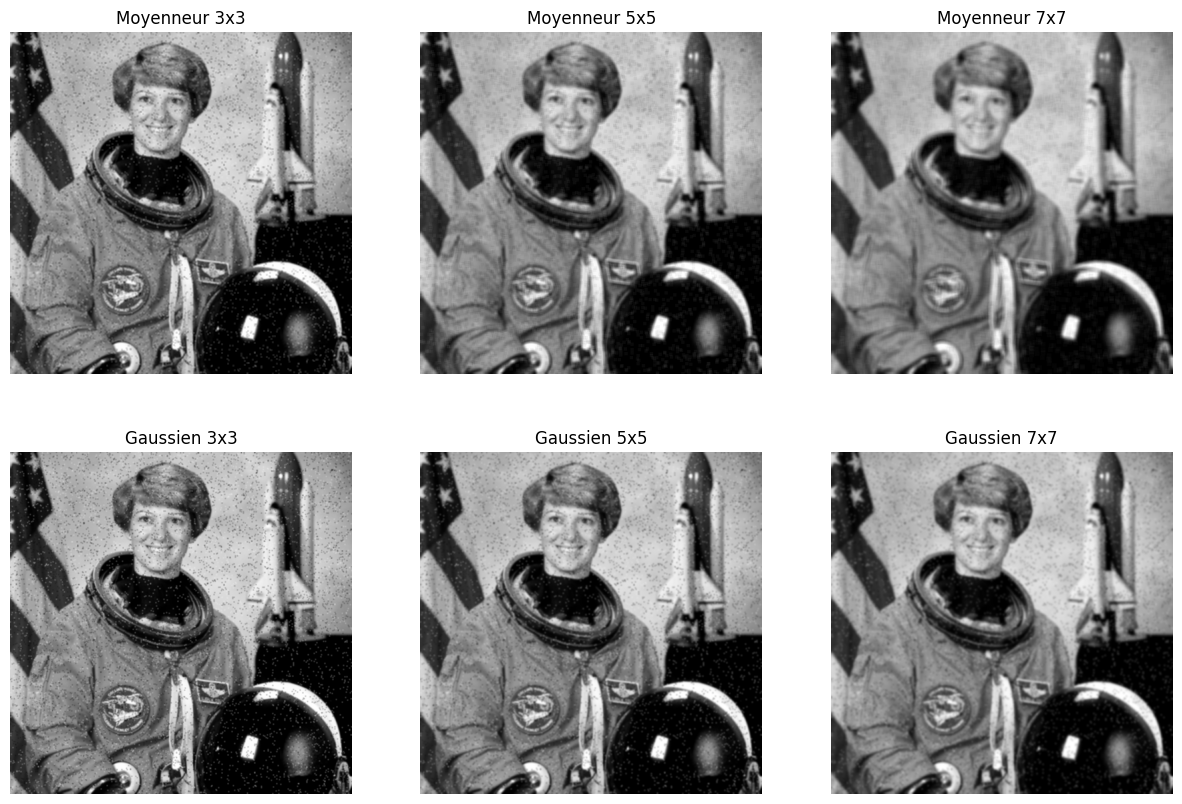

In [14]:
gaussian_3x3 = cv2.GaussianBlur(img, (3, 3), 0)
gaussian_5x5 = cv2.GaussianBlur(img, (5, 5), 0)
gaussian_7x7 = cv2.GaussianBlur(img, (7, 7), 0)
average_3x3 = cv2.blur(img, (3, 3))
average_5x5 = cv2.blur(img, (5, 5))
average_7x7 = cv2.blur(img, (7, 7))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
lignes = [[("Moyenneur 3x3", average_3x3), ("Moyenneur 5x5", average_5x5), ("Moyenneur 7x7", average_7x7)],
          [("Gaussien 3x3", gaussian_3x3), ("Gaussien 5x5", gaussian_5x5), ("Gaussien 7x7", gaussian_7x7)]]
for i in range(2):
    for j in range(3):
        t, im = lignes[i][j]
        axes[i, j].imshow(im, cmap='gray'); axes[i, j].set_title(t); axes[i, j].axis('off')
plt.show()

### Différents sigma : 1, 5, 10

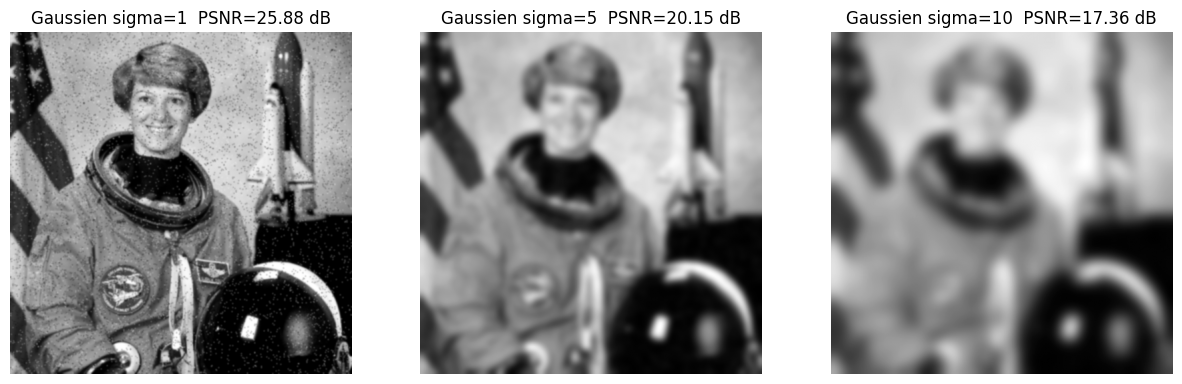

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for a, s in zip(axes, [1, 5, 10]):
    g = cv2.GaussianBlur(img, (0, 0), sigmaX=s)
    a.imshow(g, cmap='gray'); a.set_title(f"Gaussien sigma={s}  PSNR={psnr(ref, g):.2f} dB"); a.axis('off')
plt.show()

## 5. Filtre médian
### Efficacité contre le bruit poivre et sel

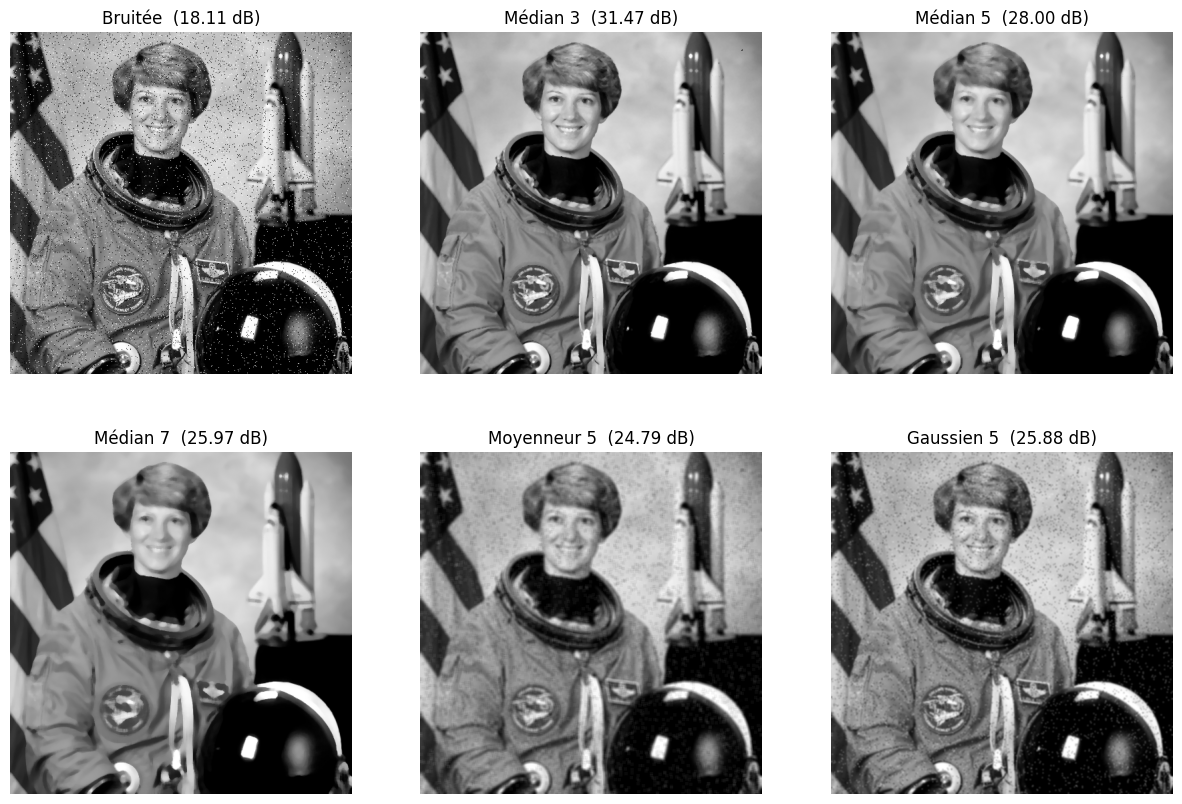

In [16]:
median_3 = cv2.medianBlur(img, 3)
median_5 = cv2.medianBlur(img, 5)
median_7 = cv2.medianBlur(img, 7)
average_5 = cv2.blur(img, (5, 5))
gaussian_5 = cv2.GaussianBlur(img, (5, 5), 0)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
liste = [("Bruitée", img), ("Médian 3", median_3), ("Médian 5", median_5),
         ("Médian 7", median_7), ("Moyenneur 5", average_5), ("Gaussien 5", gaussian_5)]
for a, (t, im) in zip(axes.ravel(), liste):
    a.imshow(im, cmap='gray'); a.set_title(f"{t}  ({psnr(ref, im):.2f} dB)"); a.axis('off')
plt.show()

### Question 2 : filtre médian sur bruit gaussien

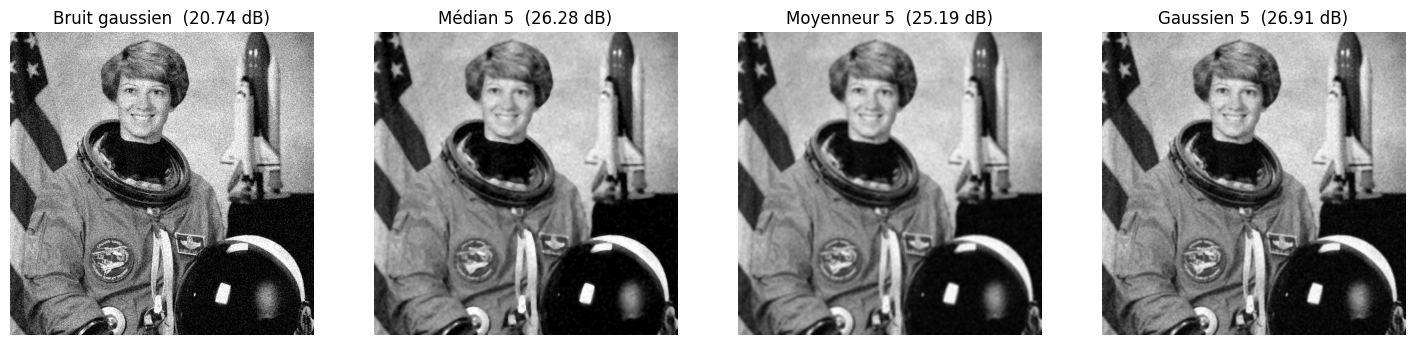

In [17]:
sigma_bruit = 25
bruit = np.random.normal(0, sigma_bruit, ref.shape)
img_gauss = np.clip(ref.astype(float) + bruit, 0, 255).astype(np.uint8)

med = cv2.medianBlur(img_gauss, 5)
moy = cv2.blur(img_gauss, (5, 5))
gau = cv2.GaussianBlur(img_gauss, (5, 5), 0)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for a, (t, im) in zip(axes, [("Bruit gaussien", img_gauss), ("Médian 5", med),
                             ("Moyenneur 5", moy), ("Gaussien 5", gau)]):
    a.imshow(im, cmap='gray'); a.set_title(f"{t}  ({psnr(ref, im):.2f} dB)"); a.axis('off')
plt.show()

**Conclusion :** le médian est très efficace contre le poivre et sel (les valeurs extrêmes sont éliminées par le tri), mais moins efficace que le gaussien ou le moyenneur contre un bruit gaussien, et il abîme davantage les détails fins.